# Formativa 1 · Rotación de empleados (IBM HR Employee Attrition)

**MCDI501 – Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial · Universidad Andrés Bello
Equipo: Hernán Saavedra · Lenin Morales Salas · Rodrigo Gómez · Docente: Jean Paul Maidana

**Pregunta de investigación.** ¿Se asocian las horas extra, el ingreso mensual, la satisfacción laboral
y la antigüedad en la empresa con la salida de empleados?

Este cuaderno produce **todas** las cifras, tablas y figuras del informe, en el mismo orden de sus secciones:

| Sección del cuaderno | Sección del informe |
|---|---|
| 0. Configuración | 5. Documentación |
| 1. Calidad de los datos · 2. Tipos de variables | 1. Introducción |
| 3. Faltantes MCAR · 4. Descriptiva · 5. Figuras | 2. Estadística descriptiva |
| 6. Intervalos de confianza | 3. Estimación puntual e IC |
| 7. Pruebas de hipótesis | 4. Prueba de hipótesis |
| 8. Resumen de resultados | 6. Interpretación |

Para reproducir: `Kernel → Restart Kernel and Run All Cells`. Las salidas se guardan en
`Formativa1/figuras/`, `Formativa1/resultados/` y `datos/processed/`.

## 0. Configuración

Librerías, semilla, rutas y versiones del entorno. La semilla (`SEMILLA = 42`) controla la única etapa
aleatoria del análisis: la generación de faltantes MCAR. La raíz del repositorio se detecta para que el
cuaderno corra igual desde la carpeta `Formativa1/` o desde la raíz.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
ALFA = 0.05
OBJETIVO = 'Attrition'

# Raíz del repositorio: la carpeta que contiene 'datos/'
RAIZ = Path.cwd()
while not (RAIZ / 'datos').is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
RUTA_RAW = RAIZ / 'datos' / 'raw' / 'WA_Fn-UseC_-HR-Employee-Attrition.csv'
DIR_PROC = RAIZ / 'datos' / 'processed'
DIR_FIG = RAIZ / 'Formativa1' / 'figuras'
DIR_RES = RAIZ / 'Formativa1' / 'resultados'
for d in (DIR_PROC, DIR_FIG, DIR_RES):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 30)

print('Python    :', sys.version.split()[0])
print('pandas    :', pd.__version__, '| NumPy:', np.__version__, '| SciPy:', scipy.__version__)
print('Matplotlib:', matplotlib.__version__, '| seaborn:', sns.__version__)
print('Datos     :', RUTA_RAW.relative_to(RAIZ))

Python    : 3.13.16
pandas    : 3.0.5 | NumPy: 2.5.3 | SciPy: 1.18.1
Matplotlib: 3.11.2 | seaborn: 0.13.2
Datos     : datos/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv


### Estilo común de las figuras
Una sola convención de color en todo el informe: **azul = permaneció**, **naranja = salió**.
Ejes y títulos en español; las figuras se guardan a 200 dpi para el PDF.

In [2]:
AZUL, NARANJA = '#2a78d6', '#eb6834'
GRIS, TINTA = '#8a8984', '#2b2b29'
COLORES_SALIDA = {'No': AZUL, 'Yes': NARANJA}
ETIQUETAS_SALIDA = {'No': 'Permaneció', 'Yes': 'Salió'}

plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.labelcolor': TINTA, 'xtick.color': TINTA, 'ytick.color': TINTA,
    'axes.edgecolor': '#c9c8c2', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

## 1. Calidad de los datos

Antes de describir, se verifica que el archivo sea el esperado: dimensiones, faltantes, duplicados,
unicidad del identificador y columnas constantes. Cada verificación termina en un `assert`, de modo que
si el archivo cambia el cuaderno se detiene en el punto exacto del problema.

In [3]:
def cargar_datos(ruta):
    # Lee el CSV original sin modificarlo.
    return pd.read_csv(ruta)


def diagnostico_calidad(df, id_col='EmployeeNumber'):
    # Resume los problemas de calidad más comunes en un diccionario.
    return {
        'filas': df.shape[0],
        'columnas': df.shape[1],
        'celdas_faltantes': int(df.isna().sum().sum()),
        'filas_duplicadas': int(df.duplicated().sum()),
        'id_unico': bool(df[id_col].is_unique),
        'constantes': df.columns[df.nunique().eq(1)].tolist(),
    }


original = cargar_datos(RUTA_RAW)
calidad = diagnostico_calidad(original)
for k, v in calidad.items():
    print(f'{k:17}: {v}')

assert original.shape == (1470, 35), 'El archivo no tiene las dimensiones esperadas'
assert calidad['celdas_faltantes'] == 0 and calidad['filas_duplicadas'] == 0
assert calidad['id_unico']
CONSTANTES = calidad['constantes']

filas            : 1470
columnas         : 35
celdas_faltantes : 0
filas_duplicadas : 0
id_unico         : True
constantes       : ['EmployeeCount', 'Over18', 'StandardHours']


**Lectura.** El archivo llega limpio: 1.470 registros, 35 columnas, sin faltantes ni duplicados y con un
identificador único. Tres columnas son constantes (`EmployeeCount`, `Over18`, `StandardHours`): no
aportan variación, por lo que se excluyen del análisis junto con el identificador.

## 2. Tipos de variables

La clasificación sigue el esquema del curso: cualitativas (nominales u ordinales) y cuantitativas
(discretas = se cuentan, continuas = se miden). Tres decisiones que conviene justificar:

- **Escalas de 1 a 4** (satisfacción, involucramiento, balance vida-trabajo) y niveles (`JobLevel`,
  `StockOptionLevel`, `Education`) son **ordinales** aunque se almacenen como enteros: el orden tiene
  sentido, pero la distancia entre niveles no es necesariamente igual.
- **`BusinessTravel` es ordinal**: *Non-Travel < Travel_Rarely < Travel_Frequently* expresa frecuencia
  creciente. Se declara el orden explícitamente para que pandas no lo ordene alfabéticamente.
- **Edad y antigüedades son continuas** (miden tiempo), aunque estén registradas en años enteros.
  Solo los conteos de eventos (empresas anteriores, capacitaciones) son discretos.

La columna *Rol* indica cómo entra cada variable en este informe.

In [4]:
CLASIFICACION = {
    'Cualitativa nominal': ['Attrition', 'OverTime', 'Gender', 'Department', 'EducationField',
                            'JobRole', 'MaritalStatus'],
    'Cualitativa ordinal': ['BusinessTravel', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement',
                            'JobLevel', 'JobSatisfaction', 'PerformanceRating',
                            'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance'],
    'Cuantitativa discreta': ['NumCompaniesWorked', 'TrainingTimesLastYear'],
    'Cuantitativa continua': ['Age', 'DistanceFromHome', 'PercentSalaryHike', 'TotalWorkingYears',
                              'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
                              'YearsWithCurrManager', 'MonthlyIncome', 'DailyRate', 'HourlyRate',
                              'MonthlyRate'],
    'Excluida': ['EmployeeNumber'] + CONSTANTES,
}
EXPLICATIVAS = ['OverTime', 'MonthlyIncome', 'JobSatisfaction', 'YearsAtCompany']


def construir_diccionario(df, clasificacion):
    # Tabla variable a variable: tipo estadístico, tipo de almacenamiento y rol en el análisis.
    tipo = {v: t for t, vs in clasificacion.items() for v in vs}
    filas = []
    for v in df.columns:
        if v == OBJETIVO:
            rol = 'Objetivo'
        elif v in EXPLICATIVAS:
            rol = 'Explicativa (pregunta)'
        elif tipo[v] == 'Excluida':
            rol = 'Excluida (identificador)' if v == 'EmployeeNumber' else 'Excluida (constante)'
        else:
            rol = 'Contexto'
        filas.append({'Variable': v, 'Tipo estadístico': tipo[v], 'Tipo en Python': str(df[v].dtype),
                      'Valores distintos': df[v].nunique(), 'Rol': rol})
    return pd.DataFrame(filas)


diccionario = construir_diccionario(original, CLASIFICACION)
assert set(diccionario['Variable']) == set(original.columns), 'Hay variables sin clasificar'
assert diccionario['Variable'].is_unique, 'Una variable quedó en dos tipos'
diccionario.to_csv(DIR_RES / 'diccionario_variables.csv', index=False)

print(diccionario.groupby('Tipo estadístico').size().rename('n variables'), '\n')
diccionario

Tipo estadístico
Cualitativa nominal       7
Cualitativa ordinal      10
Cuantitativa continua    12
Cuantitativa discreta     2
Excluida                  4
Name: n variables, dtype: int64 



,Variable,Tipo estadístico,Tipo en Python,Valores distintos,Rol
0,Age,Cuantitativa continua,int64,43,Contexto
1,Attrition,Cualitativa nominal,str,2,Objetivo
2,BusinessTravel,Cualitativa ordinal,str,3,Contexto
3,DailyRate,Cuantitativa continua,int64,886,Contexto
4,Department,Cualitativa nominal,str,3,Contexto
5,DistanceFromHome,Cuantitativa continua,int64,29,Contexto
6,Education,Cualitativa ordinal,int64,5,Contexto
7,EducationField,Cualitativa nominal,str,6,Contexto
8,EmployeeCount,Excluida,int64,1,Excluida (constante)
9,EmployeeNumber,Excluida,int64,1470,Excluida (identificador)


## 3. Preparación: faltantes MCAR

El dataset no trae faltantes. Siguiendo el apunte de datasets del curso, se genera un **10 % de faltantes
MCAR** (*Missing Completely At Random*) en `MonthlyIncome` y `DistanceFromHome`: las posiciones se eligen
al azar, sin mirar ningún valor, así que la ausencia no depende de nada observado ni no observado.

- Se trabaja sobre una **copia**; el CSV original no se toca.
- Los valores retirados se **guardan en disco** (`datos/processed/mcar_valores_reservados.csv`) para
  evaluar imputaciones en la Sumativa 3.
- En este informe **no se imputa**: los cálculos de ingreso y distancia usan los valores observados
  (*n* = 1.323). Bajo MCAR esto no introduce sesgo; solo reduce la precisión.

In [5]:
def generar_mcar(df, columnas, fraccion, semilla, id_col='EmployeeNumber'):
    # Oculta al azar una fracción de valores por columna. Devuelve la copia con NaN y los valores retirados.
    rng = np.random.default_rng(semilla)
    datos = df.copy(deep=True)
    n_ocultar = round(len(datos) * fraccion)
    reservados = []
    for col in columnas:
        idx = rng.choice(datos.index.to_numpy(), size=n_ocultar, replace=False)
        reservados.append(pd.DataFrame({id_col: datos.loc[idx, id_col].to_numpy(), 'variable': col,
                                        'valor_original': datos.loc[idx, col].to_numpy()}))
        datos[col] = datos[col].astype(float)
        datos.loc[idx, col] = np.nan
    return datos, pd.concat(reservados, ignore_index=True)


COLS_MCAR = ['MonthlyIncome', 'DistanceFromHome']
datos_mcar, valores_reservados = generar_mcar(original, COLS_MCAR, fraccion=0.10, semilla=SEMILLA)

faltantes = datos_mcar.isna().sum()
print(faltantes[faltantes > 0])
assert (faltantes[COLS_MCAR] == 147).all() and faltantes.drop(COLS_MCAR).eq(0).all()
assert original.isna().sum().sum() == 0, 'El original no debe modificarse'

# Los valores reservados coinciden con el original (permite evaluar imputaciones después)
chequeo = valores_reservados.merge(original, on='EmployeeNumber')
assert all((chequeo.loc[chequeo.variable == c, 'valor_original'] == chequeo.loc[chequeo.variable == c, c]).all()
           for c in COLS_MCAR)

datos_mcar.to_csv(DIR_PROC / 'ibm_hr_mcar.csv', index=False)
valores_reservados.to_csv(DIR_PROC / 'mcar_valores_reservados.csv', index=False)

# Base de análisis: sin identificador ni constantes; BusinessTravel con su orden declarado
analisis = datos_mcar.drop(columns=CLASIFICACION['Excluida'])
analisis['BusinessTravel'] = pd.Categorical(
    analisis['BusinessTravel'], ordered=True,
    categories=['Non-Travel', 'Travel_Rarely', 'Travel_Frequently'])
print('Base de análisis:', analisis.shape)

DistanceFromHome    147
MonthlyIncome       147
dtype: int64
Base de análisis: (1470, 31)


**Verificación MCAR.** Si los faltantes son realmente al azar, la proporción de salida entre los registros
con ingreso oculto debería parecerse a la del resto. Se compara con una prueba exacta de Fisher
(tabla 2×2); un p-valor alto es coherente con el mecanismo MCAR.

In [6]:
oculto = analisis['MonthlyIncome'].isna()
tabla_mcar = pd.crosstab(oculto, analisis[OBJETIVO])
print(tabla_mcar)
print('Salida (%) según ingreso oculto:', (100 * tabla_mcar['Yes'] / tabla_mcar.sum(axis=1)).round(2).to_dict())
print(f"Fisher: p = {stats.fisher_exact(tabla_mcar.to_numpy())[1]:.3f}")

Attrition        No  Yes
MonthlyIncome           
False          1113  210
True            120   27
Salida (%) según ingreso oculto: {False: 15.87, True: 18.37}
Fisher: p = 0.410


## 4. Estadística descriptiva

### 4.1 Variable objetivo y variables categóricas de la pregunta
Para una variable cualitativa, las medidas adecuadas son frecuencias y porcentajes (la moda es la categoría
más frecuente); para una ordinal también tiene sentido la mediana.

In [7]:
def tabla_frecuencias(serie):
    # Frecuencias absolutas y relativas, respetando el orden de las categorías.
    f = serie.value_counts(sort=False).sort_index()
    return pd.DataFrame({'n': f, '%': (100 * f / f.sum()).round(2)})


for col in [OBJETIVO, 'OverTime', 'JobSatisfaction']:
    print(f'— {col}')
    print(tabla_frecuencias(analisis[col]), '\n')
print('Mediana de JobSatisfaction:', analisis['JobSatisfaction'].median())

— Attrition
              n      %
Attrition             
No         1233  83.88
Yes         237  16.12 

— OverTime
             n     %
OverTime            
No        1054  71.7
Yes        416  28.3 

— JobSatisfaction
                   n      %
JobSatisfaction            
1                289  19.66
2                280  19.05
3                442  30.07
4                459  31.22 

Mediana de JobSatisfaction: 3.0


### 4.2 Variables cuantitativas: tendencia central, dispersión y forma
Se reportan media y mediana (centro), desviación estándar, rango intercuartílico y coeficiente de
variación (dispersión) y asimetría (forma). *n* es el tamaño efectivo: 1.323 donde hay faltantes MCAR.

In [8]:
def resumen_numerico(df, columnas):
    # Tabla 1 del informe: medidas de centro, dispersión y forma con n efectivo.
    filas = {}
    for c in columnas:
        x = df[c].dropna()
        filas[c] = {'n': len(x), 'Media': x.mean(), 'Mediana': x.median(), 'DE': x.std(ddof=1),
                    'CV (%)': 100 * x.std(ddof=1) / x.mean(), 'Mín': x.min(), 'Q1': x.quantile(.25),
                    'Q3': x.quantile(.75), 'Máx': x.max(), 'Asimetría': x.skew()}
    return pd.DataFrame(filas).T


NUMERICAS = ['Age', 'MonthlyIncome', 'YearsAtCompany', 'TotalWorkingYears', 'DistanceFromHome']
tabla1 = resumen_numerico(analisis, NUMERICAS)
tabla1.round(2).to_csv(DIR_RES / 'tabla1_descriptiva.csv')
tabla1.round(2)

,n,Media,Mediana,DE,CV (%),Mín,Q1,Q3,Máx,Asimetría
Age,1470.0,36.92,36.0,9.14,24.74,18.0,30.0,43.0,60.0,0.41
MonthlyIncome,1323.0,6530.21,4960.0,4708.33,72.10,1009.0,2930.5,8404.0,19999.0,1.36
YearsAtCompany,1470.0,7.01,5.0,6.13,87.42,0.0,3.0,9.0,40.0,1.76
TotalWorkingYears,1470.0,11.28,10.0,7.78,68.98,0.0,6.0,15.0,40.0,1.12
DistanceFromHome,1323.0,9.18,7.0,8.09,88.14,1.0,2.0,14.0,29.0,0.95


### 4.3 Comparación según salida
La pregunta es sobre **asociación con la salida**, así que la descripción clave separa a quienes salieron
de quienes permanecieron. Para las cuantitativas se compara media y mediana por grupo; para las
categóricas, el porcentaje de salida dentro de cada categoría, con su intervalo de Wilson del 95 %.

In [9]:
def comparar_por_salida(df, columnas, grupo=OBJETIVO):
    # Media, mediana y DE de cada variable cuantitativa según el grupo de salida.
    t = df.groupby(grupo, observed=True)[columnas].agg(['count', 'mean', 'median', 'std'])
    return t.T.unstack(level=1).round(2)


def ic_wilson(k, n, conf=0.95):
    # Intervalo de Wilson para una proporción k/n.
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - margen, centro + margen


def tasa_salida_por_categoria(df, col, objetivo=OBJETIVO):
    # % de salida dentro de cada categoría, con IC de Wilson del 95 %.
    g = df.groupby(col, observed=True)[objetivo]
    t = pd.DataFrame({'n': g.size(), 'salidas': g.apply(lambda s: s.eq('Yes').sum())})
    t['% salida'] = 100 * t['salidas'] / t['n']
    ic = [ic_wilson(k, n) for k, n in zip(t['salidas'], t['n'])]
    t['IC inf'] = [100 * a for a, _ in ic]
    t['IC sup'] = [100 * b for _, b in ic]
    return t.round(2)


tabla2 = comparar_por_salida(analisis, NUMERICAS)
tabla2.to_csv(DIR_RES / 'tabla2_por_salida.csv')
print(tabla2, '\n')

tasas = {c: tasa_salida_por_categoria(analisis, c) for c in ['OverTime', 'JobSatisfaction']}
for c, t in tasas.items():
    print(f'— % de salida según {c}')
    print(t, '\n')
pd.concat(tasas, names=['Variable', 'Categoría']).to_csv(DIR_RES / 'tabla3_tasas_salida.csv')

# Antigüedad agrupada en tramos (solo para describir y graficar)
analisis['TramoAntiguedad'] = pd.cut(analisis['YearsAtCompany'], bins=[-1, 2, 5, 10, 41],
                                     labels=['0–2', '3–5', '6–10', '11+'])
tasas['TramoAntiguedad'] = tasa_salida_por_categoria(analisis, 'TramoAntiguedad')
print('— % de salida según tramo de antigüedad (años)')
print(tasas['TramoAntiguedad'])

Attrition              No                              Yes                          
                    count     mean  median      std  count     mean  median      std
Age                1233.0    37.56    36.0     8.89  237.0    33.61    32.0     9.69
MonthlyIncome      1113.0  6878.23  5228.0  4816.71  210.0  4685.71  3150.5  3566.28
YearsAtCompany     1233.0     7.37     6.0     6.10  237.0     5.13     3.0     5.95
TotalWorkingYears  1233.0    11.86    10.0     7.76  237.0     8.24     7.0     7.17
DistanceFromHome   1107.0     8.90     7.0     8.01  216.0    10.64     9.0     8.38 

— % de salida según OverTime
             n  salidas  % salida  IC inf  IC sup
OverTime                                         
No        1054      110     10.44    8.73   12.43
Yes        416      127     30.53   26.30   35.12 

— % de salida según JobSatisfaction
                   n  salidas  % salida  IC inf  IC sup
JobSatisfaction                                        
1                289    

## 5. Figuras

Cada gráfico corresponde al tipo de variable: **barras** para la objetivo (cualitativa), **histogramas**
para las cuantitativas, **cajas** para comparar una cuantitativa entre grupos y **barras con IC** para
el porcentaje de salida por categoría.

Guardada: Formativa1/figuras/fig1_objetivo_distribuciones.png


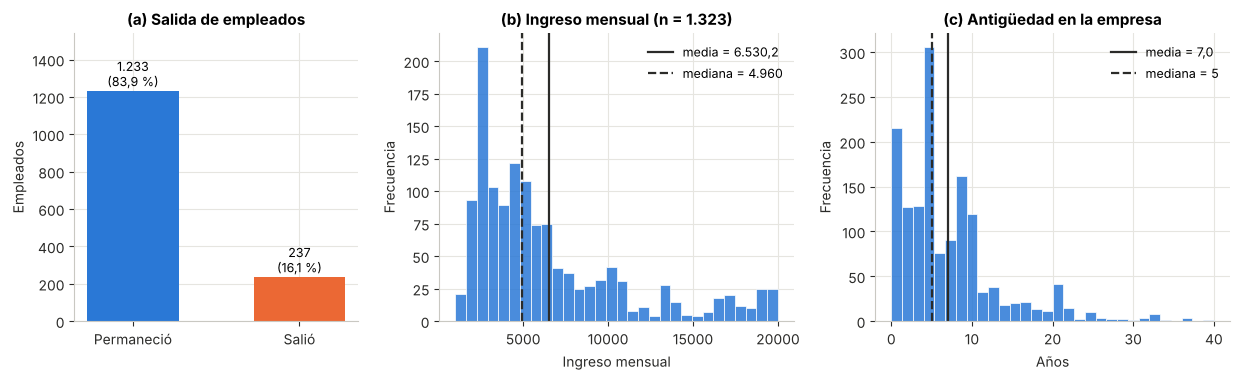

In [10]:
def guardar(fig, nombre):
    fig.savefig(DIR_FIG / nombre)
    print('Guardada:', (DIR_FIG / nombre).relative_to(RAIZ))


# Figura 1 · Objetivo y distribuciones
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw={'width_ratios': [0.8, 1, 1]})
vc = analisis[OBJETIVO].value_counts().reindex(['No', 'Yes'])
ax[0].bar([ETIQUETAS_SALIDA[k] for k in vc.index], vc.values, color=[AZUL, NARANJA], width=0.55)
for i, v in enumerate(vc.values):
    ax[0].text(i, v + 25, f'{v:,}'.replace(',', '.') + f'\n({100 * v / vc.sum():.1f} %)'.replace('.', ','), ha='center', fontsize=9)
ax[0].set_ylim(0, vc.max() * 1.25)
ax[0].set_ylabel('Empleados')
ax[0].set_title('(a) Salida de empleados')

for a, col, titulo, xlab in [(ax[1], 'MonthlyIncome', '(b) Ingreso mensual (n = 1.323)', 'Ingreso mensual'),
                             (ax[2], 'YearsAtCompany', '(c) Antigüedad en la empresa', 'Años')]:
    x = analisis[col].dropna()
    a.hist(x, bins=30, color=AZUL, alpha=0.85, edgecolor='white', linewidth=0.6)
    a.axvline(x.mean(), color=TINTA, ls='-', lw=1.6, label=f'media = {x.mean():,.1f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
    a.axvline(x.median(), color=TINTA, ls='--', lw=1.6, label=f'mediana = {x.median():,.0f}'.replace(',', '.'))
    a.set_xlabel(xlab)
    a.set_ylabel('Frecuencia')
    a.set_title(titulo)
    a.legend(frameon=False, fontsize=9)
fig.tight_layout()
guardar(fig, 'fig1_objetivo_distribuciones.png')
plt.show()

Guardada: Formativa1/figuras/fig2_comparacion_salida.png


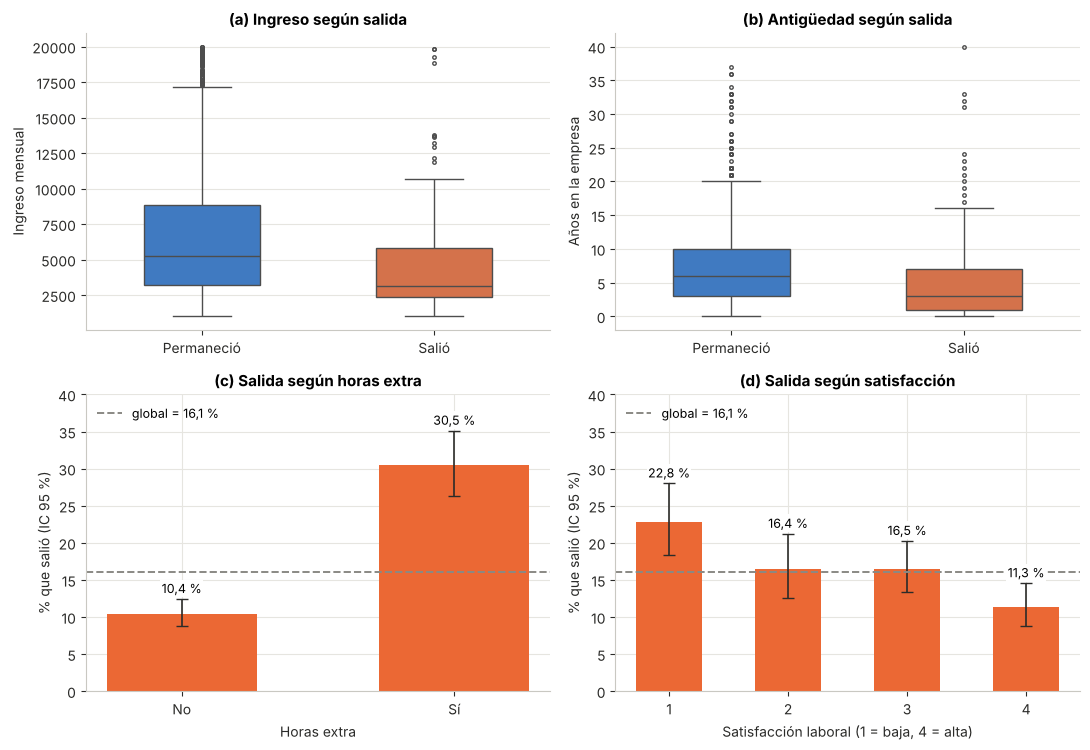

In [11]:
# Figura 2 · Comparación según salida: cuantitativas (cajas) y categóricas (% de salida con IC)
fig, ax = plt.subplots(2, 2, figsize=(11, 7.6))
ax = ax.ravel()

for a, col, titulo, ylab in [(ax[0], 'MonthlyIncome', '(a) Ingreso según salida', 'Ingreso mensual'),
                             (ax[1], 'YearsAtCompany', '(b) Antigüedad según salida', 'Años en la empresa')]:
    sns.boxplot(data=analisis, x=OBJETIVO, y=col, hue=OBJETIVO, order=['No', 'Yes'], palette=COLORES_SALIDA,
                width=0.5, linewidth=1, fliersize=2.5, legend=False, ax=a)
    a.set_xticks([0, 1], [ETIQUETAS_SALIDA['No'], ETIQUETAS_SALIDA['Yes']])
    a.set_xlabel('')
    a.set_ylabel(ylab)
    a.set_title(titulo)

media_global = 100 * analisis[OBJETIVO].eq('Yes').mean()
for a, col, titulo, xlab, etiquetas in [
        (ax[2], 'OverTime', '(c) Salida según horas extra', 'Horas extra', {'No': 'No', 'Yes': 'Sí'}),
        (ax[3], 'JobSatisfaction', '(d) Salida según satisfacción', 'Satisfacción laboral (1 = baja, 4 = alta)', None)]:
    t = tasas[col]
    pos = np.arange(len(t))
    err = np.vstack([t['% salida'] - t['IC inf'], t['IC sup'] - t['% salida']])
    a.bar(pos, t['% salida'], color=NARANJA, width=0.55)
    a.errorbar(pos, t['% salida'], yerr=err, fmt='none', ecolor=TINTA, elinewidth=1.2, capsize=4)
    for p_, v, sup in zip(pos, t['% salida'], t['IC sup']):
        a.text(p_, sup + 0.8, f'{v:.1f} %'.replace('.', ','), fontsize=9, ha='center',
               bbox=dict(facecolor='white', edgecolor='none', pad=1))
    a.axhline(media_global, color=GRIS, ls='--', lw=1.4, label=f'global = {media_global:.1f} %'.replace('.', ','))
    a.set_xticks(pos, [etiquetas[k] for k in t.index] if etiquetas else [str(k) for k in t.index])
    a.set_xlabel(xlab)
    a.set_ylabel('% que salió (IC 95 %)')
    a.set_ylim(0, 40)
    a.set_title(titulo)
    a.legend(frameon=False, fontsize=9, loc='upper left')
fig.tight_layout()
guardar(fig, 'fig2_comparacion_salida.png')
plt.show()

## 6. Estimación puntual e intervalos de confianza (95 %)

- **Proporción de salida → Wilson.** Con *p̂* = 0,16 el intervalo normal simple (Wald) funciona razonable,
  pero Wilson mantiene la cobertura nominal también con proporciones pequeñas y nunca sale de [0, 1].
  Se muestra Wald al lado para comparar.
- **Ingreso medio → t de Student.** La desviación poblacional es desconocida, así que se usa *t* con
  *n* − 1 grados de libertad. El ingreso es asimétrico, pero con *n* = 1.323 el Teorema Central del
  Límite hace que la **media muestral** sea aproximadamente normal.
- **Salida por grupo de horas extra → Wilson.** Son los intervalos que se ven en la Figura 2(c).

In [12]:
def ic_media_t(x, conf=0.95):
    # Media con IC t de Student; descarta faltantes.
    x = pd.Series(x).dropna()
    return x.mean(), *stats.t.interval(conf, len(x) - 1, loc=x.mean(), scale=stats.sem(x)), len(x)


n = len(analisis)
k = int(analisis[OBJETIVO].eq('Yes').sum())
p_hat = k / n
wil = ic_wilson(k, n)
ee = np.sqrt(p_hat * (1 - p_hat) / n)
wald = (p_hat - 1.96 * ee, p_hat + 1.96 * ee)
media_ing, ing_inf, ing_sup, n_ing = ic_media_t(analisis['MonthlyIncome'])

filas = [
    {'Parámetro': 'Proporción de salida (%)', 'n': n, 'Estimación': 100 * p_hat,
     'IC inf': 100 * wil[0], 'IC sup': 100 * wil[1], 'Método': 'Wilson'},
    {'Parámetro': 'Ingreso mensual medio', 'n': n_ing, 'Estimación': media_ing,
     'IC inf': ing_inf, 'IC sup': ing_sup, 'Método': 't de Student'},
]
for g in ['No', 'Yes']:
    t = tasas['OverTime'].loc[g]
    filas.append({'Parámetro': f'Salida con horas extra = {g} (%)', 'n': int(t['n']), 'Estimación': t['% salida'],
                  'IC inf': t['IC inf'], 'IC sup': t['IC sup'], 'Método': 'Wilson'})
tabla4 = pd.DataFrame(filas).round(2)
tabla4.to_csv(DIR_RES / 'tabla4_intervalos.csv', index=False)
print(f'Wald para comparar: [{100 * wald[0]:.2f} %, {100 * wald[1]:.2f} %]')
tabla4

Wald para comparar: [14.24 %, 18.00 %]


,Parámetro,n,Estimación,IC inf,IC sup,Método
0,Proporción de salida (%),1470,16.12,14.33,18.09,Wilson
1,Ingreso mensual medio,1323,6530.21,6276.27,6784.15,t de Student
2,Salida con horas extra = No (%),1054,10.44,8.73,12.43,Wilson
3,Salida con horas extra = Yes (%),416,30.53,26.30,35.12,Wilson


## 7. Pruebas de hipótesis (α = 0,05)

Una prueba por cada variable de la pregunta, elegida según el **tipo de variable**:

| Variable | Tipo | Prueba | Tamaño del efecto |
|---|---|---|---|
| Horas extra | nominal binaria | χ² de independencia (2×2) + z de dos proporciones | V de Cramér, riesgo relativo |
| Ingreso mensual | continua, 2 grupos | *t* de Welch | *d* de Cohen |
| Satisfacción laboral | ordinal (4 niveles) | χ² de independencia (4×2) | V de Cramér |
| Antigüedad | continua, 2 grupos | *t* de Welch | *d* de Cohen |

Se usa **Welch** porque los grupos tienen tamaños muy distintos (237 vs. 1.233) y no hay razón para
suponer varianzas iguales. Como ingreso y antigüedad son asimétricas, se agrega **Mann-Whitney** como
verificación que no depende de la normalidad. Al hacer cuatro contrastes, se reporta también el umbral de
**Bonferroni** (0,05 / 4 = 0,0125) para controlar el error tipo I global.

In [13]:
def prueba_chi2(df, col, objetivo=OBJETIVO):
    # χ² de independencia sin corrección de continuidad, con V de Cramér y esperada mínima.
    tabla = pd.crosstab(df[col], df[objetivo])
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla, correction=False)
    v = np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))
    return {'estadístico': chi2, 'gl': gl, 'p': p, 'efecto': v, 'medida': 'V de Cramér',
            'esperada mín.': esperadas.min()}


def prueba_welch(df, col, objetivo=OBJETIVO):
    # t de Welch (salió vs. permaneció), d de Cohen con DE combinada y Mann-Whitney como verificación.
    a = df.loc[df[objetivo] == 'Yes', col].dropna()
    b = df.loc[df[objetivo] == 'No', col].dropna()
    res = stats.ttest_ind(a, b, equal_var=False)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return {'estadístico': res.statistic, 'gl': res.df, 'p': res.pvalue, 'efecto': (a.mean() - b.mean()) / sp,
            'medida': 'd de Cohen', 'p Mann-Whitney': stats.mannwhitneyu(a, b).pvalue,
            'n salió': len(a), 'n permaneció': len(b)}


def dos_proporciones(df, col, nivel, objetivo=OBJETIVO, conf=0.95):
    # z de dos proporciones (H0: p1 = p0), IC de la diferencia y riesgo relativo.
    y = df[objetivo].eq('Yes')
    g1, g0 = y[df[col] == nivel], y[df[col] != nivel]
    p1, p0, n1, n0 = g1.mean(), g0.mean(), len(g1), len(g0)
    pc = (g1.sum() + g0.sum()) / (n1 + n0)
    z = (p1 - p0) / np.sqrt(pc * (1 - pc) * (1 / n1 + 1 / n0))
    ee = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    zc = stats.norm.ppf(1 - (1 - conf) / 2)
    return {'p1 (%)': 100 * p1, 'p0 (%)': 100 * p0, 'diferencia (pp)': 100 * (p1 - p0),
            'IC dif. inf': 100 * (p1 - p0 - zc * ee), 'IC dif. sup': 100 * (p1 - p0 + zc * ee),
            'z': z, 'p': 2 * stats.norm.sf(abs(z)), 'riesgo relativo': p1 / p0}


resultados = {
    'Horas extra (χ²)': prueba_chi2(analisis, 'OverTime'),
    'Ingreso mensual (Welch)': prueba_welch(analisis, 'MonthlyIncome'),
    'Satisfacción laboral (χ²)': prueba_chi2(analisis, 'JobSatisfaction'),
    'Antigüedad (Welch)': prueba_welch(analisis, 'YearsAtCompany'),
}
tabla5 = pd.DataFrame(resultados).T
tabla5['Rechaza H0 (α = 0,05)'] = tabla5['p'] < ALFA
tabla5['Rechaza H0 (Bonferroni)'] = tabla5['p'] < ALFA / len(resultados)
tabla5.to_csv(DIR_RES / 'tabla5_pruebas.csv')

# Supuesto de χ²: todas las esperadas ≥ 5
assert all(r['esperada mín.'] >= 5 for r in resultados.values() if 'esperada mín.' in r)

with pd.option_context('display.float_format', '{:.4g}'.format):
    print(tabla5)

                          estadístico    gl         p  efecto       medida esperada mín. p Mann-Whitney n salió  \
Horas extra (χ²)                89.04     1 3.862e-21  0.2461  V de Cramér         67.07            NaN     NaN   
Ingreso mensual (Welch)        -7.684 369.4   1.4e-13 -0.4724   d de Cohen           NaN      1.539e-14     210   
Satisfacción laboral (χ²)       17.51     3 0.0005563  0.1091  V de Cramér         45.14            NaN     NaN   
Antigüedad (Welch)             -5.283 338.2 2.286e-07 -0.3686   d de Cohen           NaN      2.916e-13     237   

                          n permaneció  Rechaza H0 (α = 0,05)  Rechaza H0 (Bonferroni)  
Horas extra (χ²)                   NaN                   True                     True  
Ingreso mensual (Welch)           1113                   True                     True  
Satisfacción laboral (χ²)          NaN                   True                     True  
Antigüedad (Welch)                1233                   True       

### 7.1 Detalle de horas extra
Hipótesis: *H₀*: la salida es independiente de las horas extra · *H₁*: existe asociación.
La z de dos proporciones es equivalente al χ² 2×2 (*z*² = χ²), pero entrega además el intervalo de la
diferencia y el riesgo relativo, que son más fáciles de interpretar para una decisión.

In [14]:
print(pd.crosstab(analisis['OverTime'], analisis[OBJETIVO], margins=True, margins_name='Total'), '\n')
he = dos_proporciones(analisis, 'OverTime', 'Yes')
for k_, v in he.items():
    print(f'{k_:16}: {v:.4g}')
assert np.isclose(he['z'] ** 2, resultados['Horas extra (χ²)']['estadístico'])

Attrition    No  Yes  Total
OverTime                   
No          944  110   1054
Yes         289  127    416
Total      1233  237   1470 

p1 (%)          : 30.53
p0 (%)          : 10.44
diferencia (pp) : 20.09
IC dif. inf     : 15.3
IC dif. sup     : 24.89
z               : 9.436
p               : 3.862e-21
riesgo relativo : 2.925


### 7.2 Interpretación del tamaño del efecto
Referencias usuales (Cohen, 1988): *d* ≈ 0,2 pequeño, 0,5 mediano, 0,8 grande. Para la V de Cramér con
gl* = 1: 0,1 pequeño, 0,3 mediano, 0,5 grande. Son referencias generales, no umbrales rígidos.

In [15]:
def magnitud(efecto, medida):
    e = abs(efecto)
    cortes = (0.2, 0.5, 0.8) if medida == 'd de Cohen' else (0.1, 0.3, 0.5)
    return ('despreciable' if e < cortes[0] else 'pequeño' if e < cortes[1]
            else 'mediano' if e < cortes[2] else 'grande')


for nombre, r in resultados.items():
    print(f"{nombre:27} {r['medida']:12} = {r['efecto']:+.3f} → {magnitud(r['efecto'], r['medida'])}")

Horas extra (χ²)            V de Cramér  = +0.246 → pequeño
Ingreso mensual (Welch)     d de Cohen   = -0.472 → pequeño
Satisfacción laboral (χ²)   V de Cramér  = +0.109 → pequeño
Antigüedad (Welch)          d de Cohen   = -0.369 → pequeño


## 8. Resumen de resultados (cifras del informe)

Esta celda reúne las cifras que se citan en el informe, para que la correspondencia sea verificable.

In [16]:
t2 = tabla2
resumen = {
    'Salida global': f"{k}/{n} = {100 * p_hat:.2f} %  IC95 [{100 * wil[0]:.2f}; {100 * wil[1]:.2f}]",
    'Ingreso medio': f"{media_ing:.2f}  IC95 [{ing_inf:.2f}; {ing_sup:.2f}]  (n = {n_ing})",
    'Horas extra': f"{he['p1 (%)']:.2f} % vs {he['p0 (%)']:.2f} %; dif {he['diferencia (pp)']:.2f} pp "
                   f"IC95 [{he['IC dif. inf']:.2f}; {he['IC dif. sup']:.2f}]; RR {he['riesgo relativo']:.2f}",
    'Ingreso por salida (media)': f"salió {t2.loc['MonthlyIncome', ('Yes', 'mean')]:.2f} vs "
                                  f"permaneció {t2.loc['MonthlyIncome', ('No', 'mean')]:.2f}",
    'Antigüedad por salida (mediana)': f"salió {t2.loc['YearsAtCompany', ('Yes', 'median')]:.0f} vs "
                                       f"permaneció {t2.loc['YearsAtCompany', ('No', 'median')]:.0f} años",
}
for nombre, r in resultados.items():
    resumen[nombre] = (f"est = {r['estadístico']:.2f}; gl = {r['gl']:.1f}; p = {r['p']:.2e}; "
                       f"{r['medida']} = {r['efecto']:.3f} ({magnitud(r['efecto'], r['medida'])})")
for k_, v in resumen.items():
    print(f'{k_:32}: {v}')

Salida global                   : 237/1470 = 16.12 %  IC95 [14.33; 18.09]
Ingreso medio                   : 6530.21  IC95 [6276.27; 6784.15]  (n = 1323)
Horas extra                     : 30.53 % vs 10.44 %; dif 20.09 pp IC95 [15.30; 24.89]; RR 2.93
Ingreso por salida (media)      : salió 4685.71 vs permaneció 6878.23
Antigüedad por salida (mediana) : salió 3 vs permaneció 6 años
Horas extra (χ²)                : est = 89.04; gl = 1.0; p = 3.86e-21; V de Cramér = 0.246 (pequeño)
Ingreso mensual (Welch)         : est = -7.68; gl = 369.4; p = 1.40e-13; d de Cohen = -0.472 (pequeño)
Satisfacción laboral (χ²)       : est = 17.51; gl = 3.0; p = 5.56e-04; V de Cramér = 0.109 (pequeño)
Antigüedad (Welch)              : est = -5.28; gl = 338.2; p = 2.29e-07; d de Cohen = -0.369 (pequeño)
